# Continuing Declines in NSW Birds — Who, Where and Which Kinds

**Purpose.** Answer two questions with the combined Atlas + DES dataset:

| # | Research question | Angle |
|---|---|---|
| Q1 | Which species, if any, are **continuing to decline**? | Who is still going down |
| Q2A | Are declines concentrated in particular **regions**? | Where |
| Q2B | Are declines concentrated in particular **habitats or ecological groups**? | Which kinds of birds |

Each section follows the pattern **Research question → How we measured it → Answer via visual → What it means**.
A client-ready PDF of the same results (no code) is written at the end of the notebook.

*Associations only — these results show patterns in the records, not proven causes.*

## 0. Settings you can customise
Change any value below and re-run the notebook (**Kernel → Restart & Run All**). Every number, chart and
sentence in the notebook and the PDF is recalculated from these settings.

In [1]:
from pathlib import Path
import textwrap, warnings, logging
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patheffects
from matplotlib.patches import Rectangle, Patch
from matplotlib.backends.backend_pdf import PdfPages
from scipy.stats import kruskal
from IPython.display import Markdown, display

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # Segoe UI falls back to Arial/Liberation off Windows

# ---------------- CUSTOMISE HERE ----------------
DATA_PATH = next(p for p in [Path("combined_atlas_des.parquet"), Path("../combined_atlas_des.parquet")] if p.exists())
TRAITS_PATH = Path("species_traits_provisional.csv")   # diet, habitat, nest, movement, size (provisional, editable)
OUTPUT_DIR = Path("outputs")
PDF_NAME = "Continuing_Declines_Report.pdf"
REPORT_TITLE = "Continuing Declines in NSW Birds"
REPORT_SUBTITLE = "Which species are still declining, and where and which kinds"
PREPARED_FOR = "Client briefing"
PREPARED_BY = "CS-13 Combined Breeding Analysis team"

# Three Atlas windows: a species "continues to decline" if it fell from the 1st to the 2nd AND from the 2nd to the 3rd
WINDOWS = {"A": (1977, 1990), "B": (1991, 2005), "C": (2006, 2020)}
LIST_BAND = (15, 45)            # only survey lists with this many species, so list length is the same in every window
SHEETS_PER_SQUARE = 4           # survey sheets drawn per grid square in EACH window
REPEATS = 25                    # random draws averaged together
BOOTSTRAP = 400                 # resamples of grid squares for the uncertainty ranges
MIN_OCCUPANCY = 8               # % of squares a species must reach in one window to be assessed

# Q2A - map
CELL_DEG = 1.0                  # map cell size in degrees (about 100 km)
MIN_CELL_SQUARES = 4            # grid squares a map cell needs

ZONES = {"NC": "Coast", "CSC": "Coast", "TS": "Coast", "T": "Tablelands", "NTE": "Tablelands",
         "WS": "Inland", "CP": "Inland", "RP": "Inland", "A": "Inland", "MAW": "Inland"}
ZONE_ORDER = ["Coast", "Tablelands", "Inland"]
INTRODUCED = [957, 989, 991, 995, 996, 998, 999]
SPLIT_NAMES = [291, 294]        # Mallee/Australian Ringneck: a naming change, not a real change
# ------------------------------------------------

OUTPUT_DIR.mkdir(exist_ok=True)
WLAB = {k: f"{a}–{b}" for k, (a, b) in WINDOWS.items()}
EARLY, RECENT = WINDOWS["A"], WINDOWS["C"]     # first and last years, used on the PDF cover
print("Data file:", DATA_PATH.resolve())

Data file: /home/user/birdbreed/combined_atlas_des.parquet


In [2]:
# ---- Chart style (same colour-blind-safe palette as the first client report) ----
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#8c8b86", "#e6e5e1", "#ffffff"
BLUE, ORANGE, RED, GREY_PT = "#2a78d6", "#eb6834", "#e34948", "#bdbcb6"
DARK_BLUE, LIGHT_BLUE, LIGHT_RED = "#184f95", "#86b6ef", "#f4a7a6"

mpl.rcParams.update({
    "font.family": ["Segoe UI", "Arial", "Liberation Sans", "DejaVu Sans"], "font.size": 9.5, "text.color": INK,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.linewidth": 0.8,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.major.size": 0, "ytick.major.size": 0,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "pdf.fonttype": 42, "legend.frameon": False,
})
CHART_SIZE = (8.27, 5.4)        # same shape as the chart area on a PDF page
HALO = [mpl.patheffects.withStroke(linewidth=2.4, foreground="white")]

def headline(fig, title, subtitle):
    fig.text(0.07, 0.975, title, ha="left", va="top", fontsize=13, fontweight="bold", color=INK)
    fig.text(0.07, 0.915, subtitle, ha="left", va="top", fontsize=9.5, color=INK2)

def show(chart, name):
    fig = plt.figure(figsize=CHART_SIZE)
    chart(fig)
    fig.savefig(OUTPUT_DIR / f"{name}.png", dpi=200)
    plt.show()

def tidy_name(n):
    return n.title() if isinstance(n, str) and n.isupper() else n

def answer(Q):
    display(Markdown("### Answer\n" + "\n".join(f"* {f}" for f in Q["findings"]) +
                     f"\n\n**What it means:** {Q['meaning']}\n\n*Caution: {Q['caveat']}*"))

TOWNS = {"Sydney": (-33.87, 151.21), "Newcastle": (-32.93, 151.78), "Canberra": (-35.28, 149.13),
         "Dubbo": (-32.25, 148.60), "Broken Hill": (-31.95, 141.47), "Wagga Wagga": (-35.12, 147.37),
         "Armidale": (-30.51, 151.67), "Bourke": (-30.09, 145.94), "Griffith": (-34.29, 146.04),
         "Port Macquarie": (-31.43, 152.91), "Lismore": (-28.81, 153.28), "Albury": (-36.08, 146.92),
         "Bathurst": (-33.42, 149.58), "Tamworth": (-31.09, 150.93), "Moree": (-29.47, 149.84),
         "Wollongong": (-34.42, 150.89), "Nowra": (-34.88, 150.60), "Bega": (-36.67, 149.84),
         "Cooma": (-36.24, 149.12), "Goulburn": (-34.75, 149.72), "Orange": (-33.28, 149.10),
         "Mudgee": (-32.60, 149.59), "Coonabarabran": (-31.27, 149.28), "Narrabri": (-30.33, 149.78),
         "Grafton": (-29.69, 152.93), "Coffs Harbour": (-30.30, 153.11), "Taree": (-31.90, 152.46),
         "Forbes": (-33.38, 148.01), "Parkes": (-33.14, 148.17), "Cobar": (-31.50, 145.84),
         "Hay": (-34.51, 144.84), "Deniliquin": (-35.53, 144.96), "Narrandera": (-34.75, 146.55),
         "Young": (-34.31, 148.30), "Queanbeyan": (-35.35, 149.23), "Katoomba": (-33.71, 150.31),
         "Gosford": (-33.43, 151.34), "Maitland": (-32.73, 151.56), "Singleton": (-32.57, 151.17),
         "Muswellbrook": (-32.26, 150.89), "Glen Innes": (-29.74, 151.74), "Tenterfield": (-29.05, 152.02),
         "Inverell": (-29.77, 151.11), "Gunnedah": (-30.98, 150.25), "Walgett": (-30.02, 148.12),
         "Wilcannia": (-31.56, 143.38), "Ivanhoe": (-32.90, 144.30), "Balranald": (-34.64, 143.56),
         "Wentworth": (-34.11, 141.92), "Tibooburra": (-29.43, 142.01), "Nyngan": (-31.56, 147.19),
         "Lithgow": (-33.48, 150.16), "Batemans Bay": (-35.71, 150.18), "Eden": (-37.07, 149.90),
         "Tumut": (-35.30, 148.22), "Kempsey": (-31.08, 152.83), "Ballina": (-28.87, 153.56),
         "Leeton": (-34.55, 146.40), "Condobolin": (-33.09, 147.15), "West Wyalong": (-33.92, 147.21),
         "Warren": (-31.70, 147.83), "Coonamble": (-30.95, 148.39), "Brewarrina": (-29.96, 146.86),
         "Menindee": (-32.39, 142.42), "Jindabyne": (-36.42, 148.62), "Scone": (-32.05, 150.87)}

def nearest_town(lat, lon):
    k = min(TOWNS, key=lambda t: (TOWNS[t][0] - lat) ** 2 + ((TOWNS[t][1] - lon) * np.cos(np.radians(lat))) ** 2)
    dist = 111 * np.hypot(TOWNS[k][0] - lat, (TOWNS[k][1] - lon) * np.cos(np.radians(lat)))
    return k if dist < 15 else f"near {k}"

def nsw_axes(ax):
    ax.set_aspect(1 / np.cos(np.radians(33)))
    ax.set_xlim(140.8, 154); ax.set_ylim(-37.7, -28.0)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for s in ax.spines.values(): s.set_visible(False)

def label_towns(ax, towns, size=7.2):
    for t in towns:
        la, lo = TOWNS[t]
        ax.plot(lo, la, "o", ms=2.8, color=INK, zorder=5)
        ax.text(lo + 0.12, la + 0.08, t, fontsize=size, color=INK, zorder=5, path_effects=HALO)


DIV = {"much_less": "#d43d3c", "less": "#f4a7a6", "typical": "#e6e5e1", "more": "#86b6ef", "much_more": "#256abf"}

## 1. Load and prepare the data
**What we keep.** Only `usable` Atlas surveys inside NSW (collections excluded), 1977–2020. DES is not used for
trends because its recording differs from the Atlas and rates must never be pooled; the Atlas ends in March 2020.

**A fair, like-for-like comparison across three windows.** Survey lists got shorter, then longer again, over
time, and early sheets were more often kept open for months. Both change how many species a sheet records,
regardless of what the birds are doing. So we:
* use only **single-month** sheets with **15 to 45 species**, which keeps the average list length the same in
  every window;
* use only grid squares surveyed in **all three windows**, and draw the **same number of sheets (4)** from each
  square in each window, averaging 25 random draws;
* measure each species as the **share of grid squares where it was recorded**, and compare it with the
  **typical species**.

Uncertainty ranges come from resampling the grid squares 400 times.

In [3]:
cols = ["source", "sheet_id", "species_id", "common_name", "breeding", "is_collection", "year", "single_month",
        "klat", "klon", "region", "usable"]
raw = pd.read_parquet(DATA_PATH, columns=cols)
for c in ["source", "sheet_id", "common_name", "region"]:
    raw[c] = raw[c].astype("category")
data = raw[raw["usable"]].copy()
del raw
data["lat"] = -(data["klat"] // 100 + (data["klat"] % 100) / 60)    # grid codes are square centres
data["lon"] = data["klon"] // 100 + (data["klon"] % 100) / 60
data = data[data["lat"].between(-37.7, -28.0) & data["lon"].between(140.9, 153.7)]
data["square"] = data["klat"].astype(int) * 100000 + data["klon"].astype(int)
names = data.drop_duplicates("species_id").set_index("species_id")["common_name"].astype(str).map(tidy_name)

atlas = data[(data["source"] == "Atlas") & ~data["is_collection"]
             & data["year"].between(WINDOWS["A"][0], WINDOWS["C"][1])].copy()
atlas["list_len"] = atlas["sheet_id"].map(atlas.groupby("sheet_id", observed=True).size()).astype(int)
atlas = atlas[atlas["list_len"].between(*LIST_BAND) & atlas["single_month"].astype(bool)]
edges = [WINDOWS["A"][0] - 1] + [WINDOWS[k][1] for k in "ABC"]
atlas["window"] = pd.cut(atlas["year"], edges, labels=list("ABC")).astype(str)

sheets = atlas.drop_duplicates("sheet_id")[["sheet_id", "square", "window", "list_len", "region"]]
per_sq = sheets.groupby(["square", "window"]).size().unstack(fill_value=0)
SQUARES = per_sq[(per_sq[list("ABC")] >= SHEETS_PER_SQUARE).all(axis=1)].index
sheets = sheets[sheets["square"].isin(SQUARES)]
rows = atlas[atlas["sheet_id"].isin(sheets["sheet_id"])][["sheet_id", "species_id", "square", "window", "breeding"]]

det, bdet, mean_len = None, None, []
for rep in range(REPEATS):
    pick = sheets.sample(frac=1, random_state=rep)
    pick = pick[pick.groupby(["square", "window"]).cumcount() < SHEETS_PER_SQUARE]
    mean_len.append(pick.groupby("window")["list_len"].mean())
    x = rows[rows["sheet_id"].isin(pick["sheet_id"])]
    p = x.groupby(["species_id", "square", "window"]).size().gt(0).astype(float)
    b = x[x["breeding"]].groupby(["species_id", "square", "window"]).size().gt(0).astype(float)
    det = p if det is None else det.add(p, fill_value=0)
    bdet = b if bdet is None else bdet.add(b, fill_value=0)
# Probability that each species is recorded in each square and window (averaged over the draws)
det = (det / REPEATS).unstack("window", fill_value=0).reindex(columns=list("ABC"), fill_value=0)
bdet = (bdet / REPEATS).unstack("window", fill_value=0).reindex(columns=list("ABC"), fill_value=0)

sq_info = atlas.drop_duplicates("square").set_index("square").loc[SQUARES, ["lat", "lon", "region"]]
sq_info["zone"] = sq_info["region"].astype(str).map(ZONES)
display(pd.DataFrame({"years": pd.Series(WLAB), "average species per list": pd.concat(mean_len, axis=1).mean(axis=1).round(1),
                      "sheets available": sheets.groupby("window").size()}))
print(f"{len(SQUARES)} grid squares surveyed in all three windows "
      f"({sq_info['zone'].value_counts().reindex(ZONE_ORDER).to_dict()})")

,years,average species per list,sheets available
A,1977–1990,28.4,10709
B,1991–2005,26.8,30188
C,2006–2020,28.6,9524


432 grid squares surveyed in all three windows ({'Coast': 117, 'Tablelands': 135, 'Inland': 179})


---
## Q1. Which species, if any, are continuing to decline?

**Why ask this.** A species that fell once and then levelled off needs different action from one that is still
falling. A **continuing decline** — down from the first window to the second *and* from the second to the
third — is the strongest warning sign, because whatever is driving it has not stopped.

**How we measured it.** For each species: the share of grid squares where it was recorded in 1977–1990,
1991–2005 and 2006–2020, compared with the typical species. Species are grouped as:
* **Continuing decline** — down in both steps, with the recent drop and the overall drop both clear
  (95% uncertainty range entirely below "typical").
* **New decline** — a clear drop in the recent step only.
* **Declined earlier, now steady** — a clear drop in the first step, no clear drop since.
* **Increasing** — clearly up overall. Everything else shows **no clear change**.

We also check whether each continuing decliner was recorded **breeding** in fewer squares.

In [4]:
occ = det.groupby("species_id").sum() / len(SQUARES) * 100
occ = occ[occ.max(axis=1) >= MIN_OCCUPANCY].drop(SPLIT_NAMES, errors="ignore")
STEPS = {"AB": ("A", "B"), "BC": ("B", "C"), "AC": ("A", "C")}
TYPICAL = {k: (occ[b] / occ[a]).median() for k, (a, b) in STEPS.items()}
q1 = occ.copy()
q1["name"] = names.reindex(q1.index)
for k, (a, b) in STEPS.items():
    q1[k] = q1[b] / q1[a] / TYPICAL[k]          # 1 = changed like the typical species

# Uncertainty: resample grid squares
M = {w: det[w].unstack("square", fill_value=0).reindex(index=q1.index, columns=SQUARES, fill_value=0).values
     for w in "ABC"}
rng = np.random.default_rng(0)
boot = {k: [] for k in STEPS}
for _ in range(BOOTSTRAP):
    idx = rng.integers(0, len(SQUARES), len(SQUARES))
    o = {w: M[w][:, idx].mean(axis=1) for w in "ABC"}
    for k, (a, b) in STEPS.items():
        r = o[b] / o[a]
        boot[k].append(r / np.nanmedian(r))
for k in STEPS:
    arr = np.array(boot[k])
    q1[k + "_lo"], q1[k + "_hi"] = np.nanpercentile(arr, 2.5, axis=0), np.nanpercentile(arr, 97.5, axis=0)

down_recent = q1["BC_hi"] < 1
continuing = down_recent & (q1["AB"] < 1) & (q1["AC_hi"] < 1)
q1["trend"] = np.select(
    [continuing, down_recent, q1["AB_hi"] < 1, q1["AC_lo"] > 1],
    ["Continuing decline", "New decline", "Declined earlier, now steady", "Increasing"], "No clear change")
q1["introduced"] = q1.index.isin(INTRODUCED)

# Breeding check: of the sightings of each species, the share with breeding evidence (as in the first report),
# 1977-1990 vs 2006-2020, relative to the typical species (breeding was recorded less often overall)
MIN_BREEDING = 20
bs = atlas.groupby(["species_id", "window"])["breeding"].agg(["size", "sum"]).unstack(fill_value=0)
share = bs["sum"] / bs["size"]
breed_rel = share["C"] / share["A"]
breed_typ = breed_rel[bs["sum"]["A"] >= MIN_BREEDING].median()
q1["breed_records_A"] = bs["sum"]["A"].reindex(q1.index).fillna(0)
q1["breed_AC"] = (breed_rel / breed_typ).reindex(q1.index)
traits = pd.read_csv(TRAITS_PATH).set_index("species_id")
q1.sort_values("AC").round(3).to_csv(OUTPUT_DIR / "Q1_species_trends.csv")

native = q1[~q1["introduced"]]
cont = native[native["trend"] == "Continuing decline"].sort_values("AC")
cont_intro = q1[(q1["trend"] == "Continuing decline") & q1["introduced"]]
counts = native["trend"].value_counts()
cont_breed = cont[cont["breed_records_A"] >= MIN_BREEDING]
cont_ins = cont.index.isin(traits.index[traits["diet"] == "Insects"]).sum()
n_breed_down = (cont_breed["breed_AC"] < 1).sum()
display(counts.to_frame("native species"))
print("Typical species change:", {k: f"{v - 1:+.0%}" for k, v in TYPICAL.items()})
display(cont[["name", "A", "B", "C", "AB", "BC", "AC", "breed_AC"]].round(2))

,native species
trend,
Increasing,60
No clear change,42
"Declined earlier, now steady",33
Continuing decline,27
New decline,23


Typical species change: {'AB': '-4%', 'BC': '+0%', 'AC': '-4%'}


window,name,A,B,C,AB,BC,AC,breed_AC
species_id,,,,,,,,
385,Hooded Robin,14.06,7.13,3.29,0.53,0.46,0.24,0.44
337,Pallid Cuckoo,16.36,12.27,6.82,0.78,0.55,0.44,1.24
225,Little Eagle,18.11,11.56,8.14,0.66,0.70,0.47,2.69
484,Buff-rumped Thornbill,24.32,17.90,11.40,0.76,0.63,0.49,2.08
380,Scarlet Robin,16.68,10.93,7.81,0.68,0.71,0.49,1.30
260,Little Lorikeet,12.75,9.62,6.01,0.78,0.62,0.49,0.68
547,Dusky Woodswallow,40.32,25.79,20.65,0.66,0.80,0.54,0.86
369,Restless Flycatcher,41.06,30.57,21.45,0.77,0.70,0.55,0.89
416,Crested Shrike-tit,22.55,16.28,12.16,0.75,0.74,0.56,0.89


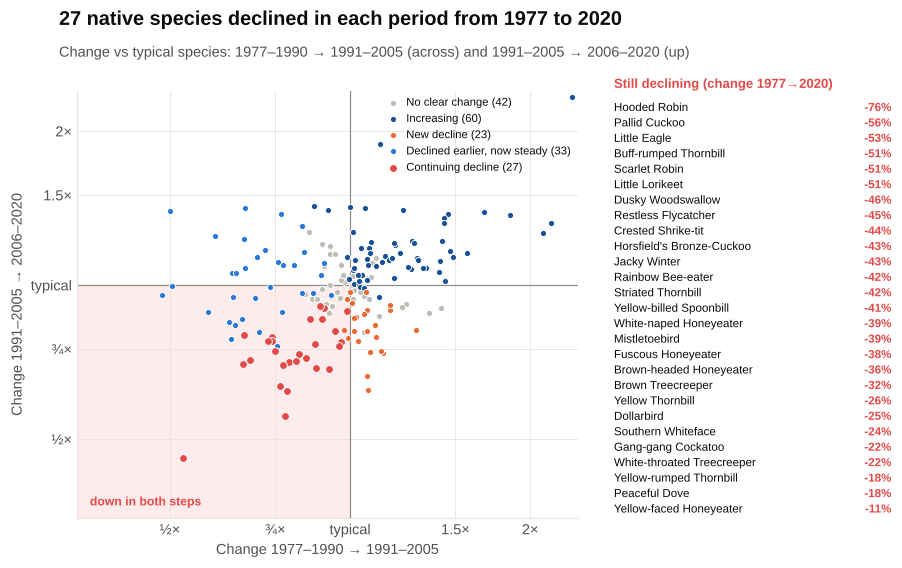

In [5]:
TREND_STYLE = {"Continuing decline": (RED, 3), "New decline": (ORANGE, 2), "Declined earlier, now steady": (BLUE, 2),
               "Increasing": (DARK_BLUE, 1), "No clear change": (GREY_PT, 0)}

def chart_q1(fig):
    headline(fig, f"{len(cont)} native species declined in each period from 1977 to 2020",
             f"Change vs typical species: {WLAB['A']} → {WLAB['B']} (across) and {WLAB['B']} → {WLAB['C']} (up)")
    ax = fig.add_gridspec(1, 1, left=0.09, right=0.64, top=0.84, bottom=0.12).subplots()
    lo, hi = 0.35, 2.4
    ax.add_patch(Rectangle((lo, lo), 1 - lo, 1 - lo, color="#fdeceb", lw=0, zorder=0))
    ax.axvline(1, color=MUTED, lw=0.8, zorder=1); ax.axhline(1, color=MUTED, lw=0.8, zorder=1)
    for t, (col, z) in sorted(TREND_STYLE.items(), key=lambda kv: kv[1][1]):
        v = native[native["trend"] == t]
        ax.scatter(v["AB"].clip(lo * 1.02, hi / 1.02), v["BC"].clip(lo * 1.02, hi / 1.02), s=26 if z == 3 else 16,
                   color=col, edgecolor="white", lw=0.6, zorder=2 + z, label=f"{t} ({len(v)})")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.minorticks_off()
    ticks = [0.5, 0.75, 1, 1.5, 2]
    labs = ["½×", "¾×", "typical", "1.5×", "2×"]
    ax.set_xticks(ticks, labs); ax.set_yticks(ticks, labs)
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    ax.set_xlabel(f"Change {WLAB['A']} → {WLAB['B']}"); ax.set_ylabel(f"Change {WLAB['B']} → {WLAB['C']}")
    ax.text(lo * 1.05, lo * 1.06, "down in both steps", fontsize=8, color=RED, fontweight="bold")
    ax.legend(loc="upper right", fontsize=7.4, handletextpad=0.2, borderaxespad=0.2)
    # Named list of the continuing decliners
    fig.text(0.68, 0.84, f"Still declining (change {WLAB['A'][:4]}→{WLAB['C'][-4:]})", fontsize=8.6,
             fontweight="bold", color=RED, va="bottom")
    n = len(cont)
    step = min(0.026, 0.72 / max(n, 1))
    size = 7.6 if n <= 28 else 6.9
    for i, (_, r) in enumerate(cont.iterrows()):
        y = 0.82 - i * step
        fig.text(0.68, y, r["name"], fontsize=size, va="top", color=INK)
        fig.text(0.985, y, f"{(r['AC'] - 1) * 100:+.0f}%", fontsize=size, va="top", ha="right", color=RED,
                 fontweight="bold")

show(chart_q1, "Q1_continuing_declines")

In [6]:
earlier = native[native["trend"] == "Declined earlier, now steady"]
new = native[native["trend"] == "New decline"]
Q1 = dict(
    question="Which species, if any, are continuing to decline?",
    why="A species that fell once and then levelled off needs different action from one that is still falling. "
        "A decline that continues across three periods means whatever is driving it has not stopped.",
    findings=[
        f"Of {len(native)} widespread native species, {len(cont)} show a continuing decline: down from {WLAB['A']} to "
        f"{WLAB['B']} and down again to {WLAB['C']}, with both the recent and overall drops clear.",
        f"The steepest are {', '.join(cont['name'].head(5))}. {cont_ins} of the {len(cont)} mainly eat insects, "
        f"such as robins, thornbills, treecreepers and woodswallows.",
        f"Breeding points the same way: for {n_breed_down} of the {len(cont_breed)} continuing decliners with enough "
        f"breeding records, a smaller share of sightings showed breeding than for the typical species.",
        f"A further {len(new)} species show a new decline since the 1990s (for example "
        f"{', '.join(new.sort_values('BC')['name'].head(3))}), while {len(earlier)} fell earlier but have been steady "
        f"since. {counts.get('Increasing', 0)} are increasing.",
    ],
    meaning="The continuing decliners are the clearest candidates for priority action and for checking against "
            "threatened-species listings. The 'new decline' group is an early warning list worth watching closely.",
    caveat=f"The Atlas ends in 2020, so 'continuing' means through {WLAB['C']}. "
           + (f"Introduced {', '.join(cont_intro['name'])} also declined steadily and are excluded from the list. "
              if len(cont_intro) else "")
           + "Results describe where species were recorded, not how many birds there are.",
)
answer(Q1)

### Answer
* Of 185 widespread native species, 27 show a continuing decline: down from 1977–1990 to 1991–2005 and down again to 2006–2020, with both the recent and overall drops clear.
* The steepest are Hooded Robin, Pallid Cuckoo, Little Eagle, Buff-rumped Thornbill, Scarlet Robin. 18 of the 27 mainly eat insects, such as robins, thornbills, treecreepers and woodswallows.
* Breeding points the same way: for 12 of the 20 continuing decliners with enough breeding records, a smaller share of sightings showed breeding than for the typical species.
* A further 23 species show a new decline since the 1990s (for example Chestnut-rumped Thornbill, White-browed Babbler, Leaden Flycatcher), while 33 fell earlier but have been steady since. 60 are increasing.

**What it means:** The continuing decliners are the clearest candidates for priority action and for checking against threatened-species listings. The 'new decline' group is an early warning list worth watching closely.

*Caution: The Atlas ends in 2020, so 'continuing' means through 2006–2020. Introduced European Goldfinch, Common Starling also declined steadily and are excluded from the list. Results describe where species were recorded, not how many birds there are.*

---
## Q2A. Are declines concentrated in particular regions?

**Why ask this.** If declines are clustered in one part of NSW, that region's land use or management is a likely
place to look; if they are spread everywhere, the pressure is statewide.

**How we measured it.**
* **Map:** NSW split into cells of about 100 km. In each cell, the median change in the share of squares where
  each species was recorded, 1977–1990 to 2006–2020 (all species recorded in at least two of the cell's squares).
* **Zones:** the same measure for Coast, Tablelands and Inland, with 95% uncertainty ranges from resampling grid
  squares, plus the share of each zone's species that lost at least 30% of their squares.
* **Where the continuing decliners fall hardest:** for each Q1 continuing decliner, the zone with its steepest drop.

In [7]:
det_sq = det.reset_index().merge(sq_info[["zone", "lat", "lon"]], left_on="square", right_index=True)
det_sq = det_sq[~det_sq["species_id"].isin(SPLIT_NAMES)]

def zone_change(sq_subset, species=None):
    # sq_subset may repeat squares (bootstrap), so weight each square by how often it was drawn
    w = pd.Series(sq_subset).value_counts()
    d = det_sq[det_sq["square"].isin(w.index)].copy()
    d[["A", "C"]] = d[["A", "C"]].mul(d["square"].map(w), axis=0)
    o = d.groupby("species_id")[["A", "C"]].sum() / len(sq_subset) * 100
    o = o[o.max(axis=1) >= 10] if species is None else o.reindex(species).fillna(0)
    return o["C"] / o["A"]

zone_rows, zone_ratio = [], {}
rng = np.random.default_rng(1)
for z in ZONE_ORDER:
    sqs = sq_info.index[sq_info["zone"] == z].values
    r = zone_ratio[z] = zone_change(sqs)
    bs = [zone_change(rng.choice(sqs, len(sqs)), r.index).median() for _ in range(200)]
    zone_rows.append(dict(zone=z, squares=len(sqs), species=len(r), median=r.median(),
                          lo=np.percentile(bs, 2.5), hi=np.percentile(bs, 97.5), down30=(r <= 0.7).mean() * 100,
                          up30=(r >= 1 / 0.7).mean() * 100))
zones = pd.DataFrame(zone_rows).set_index("zone")
zones.round(3).to_csv(OUTPUT_DIR / "Q2A_zone_summary.csv")

# Where does each continuing decliner fall hardest?
cz = pd.DataFrame({z: zone_ratio[z].reindex(cont.index) for z in ZONE_ORDER})
cz["worst"] = cz.idxmin(axis=1)
worst_zone = cz["worst"].value_counts().reindex(ZONE_ORDER, fill_value=0)
cz.insert(0, "name", cont["name"])
cz.round(2).to_csv(OUTPUT_DIR / "Q2A_continuing_decliners_by_zone.csv")

# Map cells
sq_info["cell_lat"] = np.floor(sq_info["lat"] / CELL_DEG) * CELL_DEG
sq_info["cell_lon"] = np.floor(sq_info["lon"] / CELL_DEG) * CELL_DEG
cell_rows = []
for (cla, clo), g in sq_info.groupby(["cell_lat", "cell_lon"]):
    if len(g) < MIN_CELL_SQUARES:
        continue
    d = det_sq[det_sq["square"].isin(g.index)]
    present = d.groupby("species_id")[["A", "C"]].apply(lambda v: ((v > 0).sum() >= 2).any())
    o = d[d["species_id"].isin(present[present].index)].groupby("species_id")[["A", "C"]].sum()
    o = o[(o["A"] > 0)]
    cell_rows.append(dict(cell_lat=cla, cell_lon=clo, squares=len(g), species=len(o),
                          change=(o["C"] / o["A"]).median()))
cells = pd.DataFrame(cell_rows)
BINS = [0, 0.75, 0.9, 1 / 0.9, 1 / 0.75, np.inf]
CLASS = ["much_less", "less", "typical", "more", "much_more"]
CLASS_LABEL = ["Down 25% or more", "Down 10–25%", "Within 10%", "Up 10–33%", "Up 33% or more"]
cells["cls"] = pd.cut(cells["change"], BINS, labels=CLASS, right=False)
cells.round(3).to_csv(OUTPUT_DIR / "Q2A_map_cells.csv", index=False)
display(zones.round(2)); display(worst_zone.to_frame("continuing decliners falling hardest here"))
print(f"{len(cells)} map cells; {cells['cls'].isin(['much_less', 'less']).mean():.0%} down 10% or more")

,squares,species,median,lo,hi,down30,up30
zone,,,,,,,
Coast,117,172,0.88,0.87,0.94,25.00,13.37
Tablelands,135,164,0.90,0.86,0.94,28.05,17.07
Inland,179,156,0.99,0.97,1.02,21.15,12.82


,continuing decliners falling hardest here
worst,
Coast,11
Tablelands,7
Inland,9


41 map cells; 41% down 10% or more


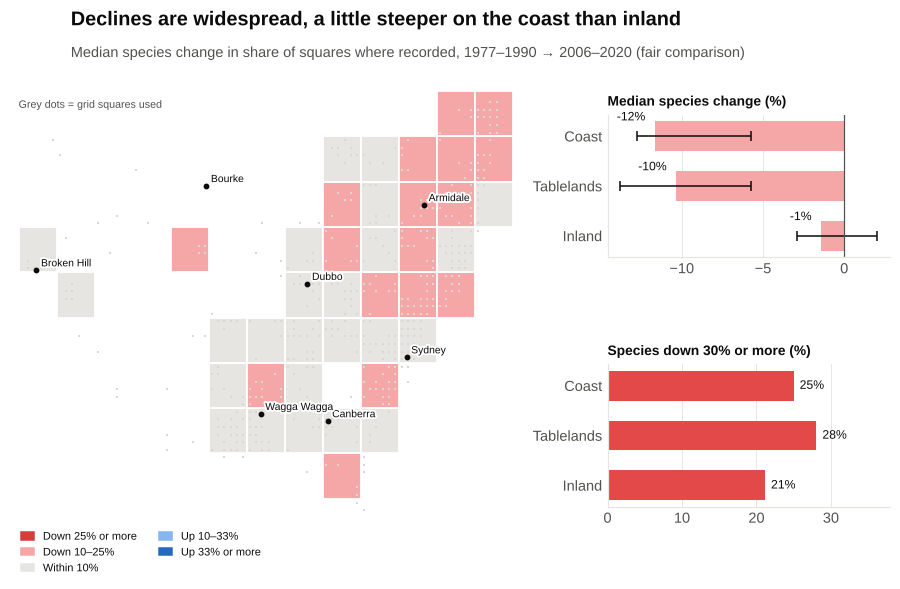

In [8]:
def chart_q2a(fig):
    worst = zones["median"].idxmin()
    headline(fig, f"Declines are widespread, a little steeper on the {worst.lower()} than inland",
             f"Median species change in share of squares where recorded, {WLAB['A']} → {WLAB['C']} (fair comparison)")
    mx = fig.add_axes([0.0, 0.10, 0.56, 0.74])
    mx.scatter(sq_info["lon"], sq_info["lat"], s=2.5, marker="s", color="#d9d8d3", lw=0, zorder=2)
    for _, r in cells.iterrows():
        mx.add_patch(Rectangle((r["cell_lon"], r["cell_lat"]), CELL_DEG, CELL_DEG, facecolor=DIV[r["cls"]],
                               edgecolor="white", lw=1.2, zorder=1))
    nsw_axes(mx)
    label_towns(mx, ["Sydney", "Canberra", "Dubbo", "Armidale", "Wagga Wagga", "Broken Hill", "Bourke"], size=6.8)
    handles = [Patch(color=DIV[c], label=l) for c, l in zip(CLASS, CLASS_LABEL)]
    mx.legend(handles=handles, loc="upper left", bbox_to_anchor=(0.0, 0.02), ncol=2, fontsize=7.2, handlelength=1.2)
    mx.text(141.0, -28.2, "Grey dots = grid squares used", fontsize=7, color=INK2, va="top")
    bx = fig.add_gridspec(2, 1, left=0.66, right=0.97, top=0.80, bottom=0.14, hspace=0.75).subplots()
    y = np.arange(len(ZONE_ORDER))[::-1]
    v = (zones["median"] - 1) * 100
    bx[0].barh(y, v, color=[DIV["less"] if x < 0 else DIV["more"] for x in v], height=0.6)
    bx[0].errorbar(v, y, xerr=[np.clip(v - (zones["lo"] - 1) * 100, 0, None),
                                     np.clip((zones["hi"] - 1) * 100 - v, 0, None)], fmt="none", ecolor=INK,
                   elinewidth=1, capsize=3)
    bx[0].set_yticks(y, ZONE_ORDER); bx[0].axvline(0, color=INK2, lw=0.8)
    bx[0].set_title("Median species change (%)", loc="left", fontsize=9, fontweight="bold")
    bx[0].grid(axis="y", visible=False)
    for yi, val in zip(y, v):
        bx[0].text(val - 0.6 if val < 0 else val + 0.6, yi + 0.38, f"{val:+.0f}%", fontsize=8, va="center",
                   ha="right" if val < 0 else "left")
    bx[1].barh(y, zones["down30"], color=RED, height=0.6)
    bx[1].set_yticks(y, ZONE_ORDER); bx[1].grid(axis="y", visible=False)
    bx[1].set_title("Species down 30% or more (%)", loc="left", fontsize=9, fontweight="bold")
    for yi, val in zip(y, zones["down30"]):
        bx[1].text(val + 0.8, yi, f"{val:.0f}%", fontsize=8, va="center")
    bx[1].set_xlim(0, zones["down30"].max() * 1.35)

show(chart_q2a, "Q2A_declines_by_region")

In [9]:
order = zones["median"].sort_values().index.tolist()
sig = zones.loc[order[0], "hi"] < zones.loc[order[-1], "lo"]
Q2A = dict(
    question="Are declines concentrated in particular regions?",
    why="Declines clustered in one part of NSW point to local land use or management; declines spread everywhere "
        "point to a statewide pressure. The answer decides whether action should be regional or statewide.",
    findings=[
        f"Declines are found in every zone, but are mild inland. The typical species lost {abs(zones.loc[order[0], 'median'] - 1):.0%} of its "
        f"squares on the {order[0].lower()}, {abs(zones.loc[order[1], 'median'] - 1):.0%} on the {order[1].lower()} "
        f"and {abs(zones.loc[order[2], 'median'] - 1):.0%} {'inland' if order[2] == 'Inland' else 'on the ' + order[2].lower()}"
        + ("." if sig else ", but the uncertainty ranges overlap, so the zones are not clearly different."),
        f"{zones.loc['Tablelands', 'down30']:.0f}% of tablelands species, {zones.loc['Coast', 'down30']:.0f}% of coastal "
        f"species and {zones.loc['Inland', 'down30']:.0f}% of inland species lost at least 30% of their squares.",
        f"On the map, {cells['cls'].isin(['much_less', 'less']).mean():.0%} of {len(cells)} cells show the median species "
        f"down by 10% or more; cells that held steady are scattered rather than forming one block.",
        f"The continuing decliners are not tied to one zone: of the {len(cont)}, "
        + ", ".join(f"{n} fall hardest {'inland' if z == 'Inland' else 'on the ' + z.lower()}"
                    for z, n in worst_zone.sort_values(ascending=False).items()) + ".",
    ],
    meaning="Presence declines are broad rather than local, so statewide measures (such as woodland protection and "
            "restoration rules) matter more than any single region. The first report found breeding fading most "
            "inland; together, the two suggest that inland birds may still be present but breeding less, while on the "
            "tablelands and coast some species are being recorded in fewer places altogether.",
    caveat="Few far-western squares were surveyed in all three windows, so the inland result rests mostly on the "
           "central west. Region names are still to be confirmed with the client, so zones are used here.",
)
answer(Q2A)

### Answer
* Declines are found in every zone, but are mild inland. The typical species lost 12% of its squares on the coast, 10% on the tablelands and 1% inland.
* 28% of tablelands species, 25% of coastal species and 21% of inland species lost at least 30% of their squares.
* On the map, 41% of 41 cells show the median species down by 10% or more; cells that held steady are scattered rather than forming one block.
* The continuing decliners are not tied to one zone: of the 27, 11 fall hardest on the coast, 9 fall hardest inland, 7 fall hardest on the tablelands.

**What it means:** Presence declines are broad rather than local, so statewide measures (such as woodland protection and restoration rules) matter more than any single region. The first report found breeding fading most inland; together, the two suggest that inland birds may still be present but breeding less, while on the tablelands and coast some species are being recorded in fewer places altogether.

*Caution: Few far-western squares were surveyed in all three windows, so the inland result rests mostly on the central west. Region names are still to be confirmed with the client, so zones are used here.*

---
## Q2B. Are declines concentrated in particular habitats or ecological groups?

**Why ask this.** If the losers share a habitat, diet or way of nesting, they probably share a pressure — and
one action (protecting a habitat, restoring insect-rich ground layers, keeping old hollow trees) can help many
species at once.

**How we measured it.** Each native species' overall change (1977–1990 to 2006–2020, relative to the typical
species, from Q1) is grouped by five traits: **main habitat, main diet, nest type, movement and body size**.
For each group we show the median change with a 95% uncertainty range, and how many of its species are Q1
continuing decliners. A test across each trait checks whether the groups differ by more than chance.

*Traits come from `species_traits_provisional.csv`, compiled for this analysis from general knowledge of each
species, using the same categories as the team's trait table. They should be checked against the team's
`Species-Traits-table.tsv` before the results are shared.*

In [10]:
traits = pd.read_csv(TRAITS_PATH).set_index("species_id")
TRAITS = [("habitat", "Main habitat"), ("diet", "Main diet"), ("nest", "Nest type"), ("movement", "Movement"),
          ("size", "Body size")]
q2b = native.join(traits[[t for t, _ in TRAITS]], how="inner")
q2b["pct"] = (q2b["AC"] - 1) * 100
q2b["cont"] = q2b["trend"] == "Continuing decline"
rng = np.random.default_rng(2)
grp_rows, tests = [], {}
for t, label in TRAITS:
    groups = {g: v for g, v in q2b.groupby(t) if len(v) >= 5}
    tests[label] = kruskal(*[v["pct"] for v in groups.values()]).pvalue
    for g, v in groups.items():
        bs = [np.median(rng.choice(v["pct"].values, len(v))) for _ in range(2000)]
        grp_rows.append(dict(trait=label, group=g, n=len(v), median=v["pct"].median(), lo=np.percentile(bs, 2.5),
                             hi=np.percentile(bs, 97.5), n_cont=int(v["cont"].sum()), share_cont=v["cont"].mean() * 100))
grp = pd.DataFrame(grp_rows)
# Holm adjustment across the five traits
p = pd.Series(tests).sort_values()
holm = pd.Series(np.minimum(1, np.maximum.accumulate(p.values * (len(p) - np.arange(len(p))))), index=p.index)
grp["trait_p"] = grp["trait"].map(holm)
grp.round(3).to_csv(OUTPUT_DIR / "Q2B_groups.csv", index=False)
missing = native.index.difference(traits.index)
display(holm.round(4).to_frame("Holm-adjusted p (do groups differ?)"))
display(grp.sort_values("median").round(1).head(8))
print(f"{len(q2b)} native species with traits; {len(missing)} without traits: {list(names.reindex(missing))}")

,Holm-adjusted p (do groups differ?)
Body size,0.0000
Main diet,0.0000
Nest type,0.0211
Movement,0.0271
Main habitat,0.0605


,trait,group,n,median,lo,hi,n_cont,share_cont,trait_p
25,Body size,Small (under 50 g),81,-17.8,-26.2,-13.2,22,27.2,0.0
15,Nest type,Dome,24,-17.1,-26.2,-6.5,5,20.8,0.0
9,Main diet,Insects,78,-16.4,-23.7,-9.1,18,23.1,0.0
14,Nest type,Brood parasite,6,-16.1,-49.9,131.6,2,33.3,0.0
22,Movement,Summer migrant,28,-15.5,-22.5,-9.5,6,21.4,0.0
6,Main habitat,Woodland,65,-15.3,-25.4,-2.0,21,32.3,0.1
1,Main habitat,Forest,39,-6.2,-13.2,9.5,5,12.8,0.1
16,Nest type,Ground or burrow,22,-3.5,-18.0,10.4,1,4.5,0.0


185 native species with traits; 0 without traits: []


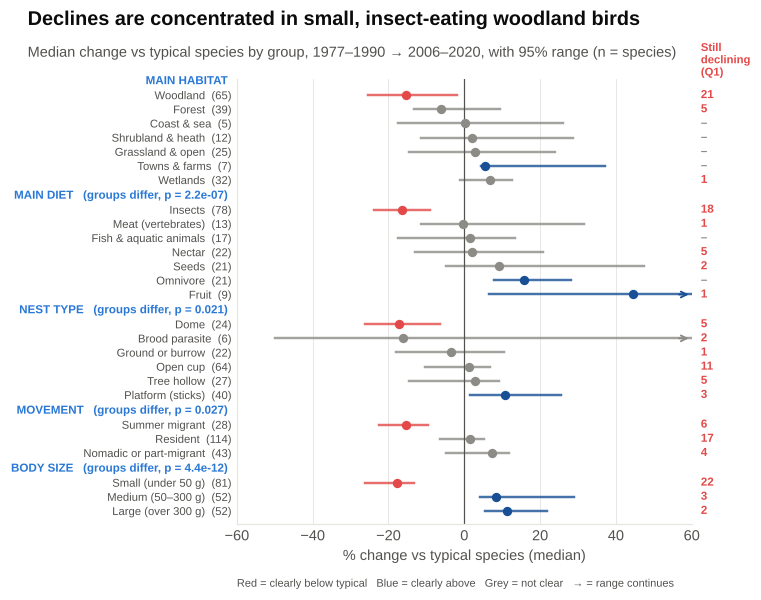

In [11]:
def chart_q2b(fig):
    lows = grp[grp["hi"] < 0].sort_values("median")
    headline(fig, "Declines are concentrated in small, insect-eating woodland birds",
             f"Median change vs typical species by group, {WLAB['A']} → {WLAB['C']}, with 95% range (n = species)")
    ax = fig.add_gridspec(1, 1, left=0.30, right=0.80, top=0.86, bottom=0.11).subplots()
    LIM = 60                      # wider ranges (very small groups) are cut off with an arrow
    y, ticks, labels, ycur = [], [], [], 0
    for t, label in TRAITS:
        g = grp[grp["trait"] == label].sort_values("median")
        ax.text(-0.02, ycur - 0.15, f"{label.upper()}" + (f"   (groups differ, p = {holm[label]:.2g})"
                if holm[label] < 0.05 else ""), transform=ax.get_yaxis_transform(), ha="right", fontsize=7.6,
                fontweight="bold", color=BLUE, va="bottom")
        ycur -= 0.75
        for _, r in g.iterrows():
            col = RED if r["hi"] < 0 else (DARK_BLUE if r["lo"] > 0 else MUTED)
            ax.plot([max(r["lo"], -LIM), min(r["hi"], LIM)], [ycur, ycur], color=col, lw=1.6, alpha=0.8)
            if r["hi"] > LIM:
                ax.annotate("", (LIM, ycur), (LIM * 0.93, ycur), arrowprops=dict(arrowstyle="->", color=col, lw=1.2))
            if r["lo"] < -LIM:
                ax.annotate("", (-LIM, ycur), (-LIM * 0.93, ycur), arrowprops=dict(arrowstyle="->", color=col, lw=1.2))
            ax.scatter(r["median"], ycur, s=26, color=col, zorder=3)
            ticks.append(ycur); labels.append(f"{r['group']}  ({r['n']})")
            ax.text(1.02, ycur, f"{r['n_cont']}" if r["n_cont"] else "–", transform=ax.get_yaxis_transform(),
                    fontsize=7.6, va="center", color=RED if r["n_cont"] else MUTED, fontweight="bold")
            ycur -= 1
        ycur -= 0.35
    ax.set_yticks(ticks, labels, fontsize=7.4)
    ax.set_ylim(ycur + 0.4, 0.4)
    ax.axvline(0, color=INK2, lw=0.8)
    ax.set_xlim(-LIM, LIM)
    ax.set_xlabel("% change vs typical species (median)")
    ax.grid(axis="y", visible=False)
    ax.text(1.02, 1.0, "Still\ndeclining\n(Q1)", transform=ax.transAxes, fontsize=7.4, color=RED, va="bottom",
            fontweight="bold")
    fig.text(0.30, 0.005, "Red = clearly below typical   Blue = clearly above   Grey = not clear   "
             "→ = range continues", fontsize=7.2, color=INK2)

show(chart_q2b, "Q2B_declines_by_group")

In [12]:
lows = grp[grp["hi"] < 0].sort_values("median")
highs = grp[grp["lo"] > 0].sort_values("median", ascending=False)
ins = grp[(grp["trait"] == "Main diet") & (grp["group"] == "Insects")].iloc[0]
diff_traits = [k for k, v in holm.items() if v < 0.05]
top_hab = grp[grp["trait"] == "Main habitat"].sort_values("median").iloc[0]
FRIENDLY = {"Small (under 50 g)": "small birds under 50 g", "Medium (50–300 g)": "medium-sized birds",
            "Large (over 300 g)": "large birds over 300 g", "Insects": "insect-eaters", "Nectar": "nectar-eaters",
            "Fruit": "fruit-eaters", "Seeds": "seed-eaters", "Omnivore": "omnivores", "Meat (vertebrates)": "meat-eaters",
            "Fish & aquatic animals": "fish- and water-feeders", "Dome": "dome-nest builders",
            "Open cup": "open-cup nesters", "Tree hollow": "hollow nesters", "Platform (sticks)": "stick-platform nesters",
            "Ground or burrow": "ground and burrow nesters", "Brood parasite": "cuckoos (brood parasites)",
            "Summer migrant": "summer migrants", "Resident": "residents", "Nomadic or part-migrant": "nomads",
            "Woodland": "woodland birds", "Forest": "forest birds", "Grassland & open": "grassland birds",
            "Wetlands": "wetland birds", "Shrubland & heath": "shrubland and heath birds",
            "Coast & sea": "coastal birds", "Towns & farms": "birds of towns and farms"}
def fmt(g): return ", ".join(f"{FRIENDLY.get(r['group'], r['group'].lower())} ({r['median']:+.0f}%)"
                             for _, r in g.iterrows())
Q2B = dict(
    question="Are declines concentrated in particular habitats or ecological groups?",
    why="Species that share a habitat, diet or nesting need probably share a pressure. Finding that shared trait "
        "means one action can help many species at once.",
    findings=[
        (f"Yes. Groups clearly below the typical species are: {fmt(lows)}." if len(lows) else
         "No group is clearly below the typical species."),
        f"Insect-eaters stand out: {ins['n_cont']} of the {len(cont)} continuing decliners eat mainly insects, and the "
        f"typical insect-eater changed by {ins['median']:+.0f}% relative to the typical species.",
        f"By habitat, {FRIENDLY.get(top_hab['group'], top_hab['group'].lower())} fared worst ({top_hab['median']:+.0f}%); "
        + (f"groups doing clearly better than typical include {fmt(highs.head(4))}." if len(highs) else
           "no habitat group did clearly better than typical."),
        (f"The groups differ by more than chance for {', '.join(t.lower() for t in diff_traits)} "
         f"(after allowing for testing five traits); for main habitat the difference is "
         f"{'also clear' if 'Main habitat' in diff_traits else 'suggestive only'}." if diff_traits else
         "After allowing for testing five traits, no trait separates the groups by more than chance; "
         "the pattern is suggestive rather than proven."),
    ],
    meaning="The shared profile of a declining bird is a small, insect-eating woodland species. Keeping and "
            "restoring woodland with a native ground layer, fallen timber and shrubs — the places these birds find "
            "insects — is the action most likely to help many decliners together.",
    caveat="Traits are provisional (compiled for this analysis) and should be checked against the team's trait table. "
           "Traits overlap — most woodland birds also eat insects — so groups are not independent.",
)
answer(Q2B)

### Answer
* Yes. Groups clearly below the typical species are: small birds under 50 g (-18%), dome-nest builders (-17%), insect-eaters (-16%), summer migrants (-15%), woodland birds (-15%).
* Insect-eaters stand out: 18 of the 27 continuing decliners eat mainly insects, and the typical insect-eater changed by -16% relative to the typical species.
* By habitat, woodland birds fared worst (-15%); groups doing clearly better than typical include fruit-eaters (+45%), omnivores (+16%), large birds over 300 g (+11%), stick-platform nesters (+11%).
* The groups differ by more than chance for body size, main diet, nest type, movement (after allowing for testing five traits); for main habitat the difference is suggestive only.

**What it means:** The shared profile of a declining bird is a small, insect-eating woodland species. Keeping and restoring woodland with a native ground layer, fallen timber and shrubs — the places these birds find insects — is the action most likely to help many decliners together.

*Caution: Traits are provisional (compiled for this analysis) and should be checked against the team's trait table. Traits overlap — most woodland birds also eat insects — so groups are not independent.*

---
## Summary — what this means for protecting bird species

In [13]:
SUMMARY = [
    ("Still declining", f"{len(cont)} native species fell in every period from 1977 to 2020, led by "
                        f"{', '.join(cont['name'].head(3))}; {len(new)} more show a new decline."),
    ("Where", f"Declines occur in every zone; the typical species lost "
              f"{abs(zones.loc[order[0], 'median'] - 1):.0%} of its squares on the {order[0].lower()} and "
              f"{abs(zones.loc[order[2], 'median'] - 1):.0%} "
              f"{'inland' if order[2] == 'Inland' else 'on the ' + order[2].lower()}."),
    ("Which kinds", "Insect-eating woodland birds are over-represented among decliners: "
                    f"{ins['n_cont']} of the {len(cont)} continuing decliners eat mainly insects."),
]
NEXT_STEPS = [
    "Check the continuing decliners against NSW and national threatened-species listings.",
    "Add the 'new decline' species to an early-warning watchlist and repeat this check as new data arrive.",
    "Prioritise woodland ground-layer, shrub and fallen-timber restoration, which supports insect-eating birds.",
    "Confirm the provisional trait table against the team's trait file before sharing the group results.",
    "Use DES surveys from 2021 onwards to test whether the continuing declines carry on after 2020.",
]
NOTES = [
    f"Records: {len(data):,} usable species records in NSW. Trends use Atlas surveys only, 1977–2020; DES "
    f"recording differs, so its rates are not pooled with the Atlas. eBird is excluded, as agreed with the client.",
    f"Fair comparison: single-month lists with {LIST_BAND[0]}–{LIST_BAND[1]} species, {SHEETS_PER_SQUARE} lists per grid "
    f"square per window in the {len(SQUARES)} squares surveyed in all three windows, averaged over {REPEATS} draws.",
    f"Each species is compared with the typical species; uncertainty ranges come from {BOOTSTRAP} resamples of squares.",
    "Traits are provisional, compiled for this analysis using the team's categories.",
    "All settings can be changed in the accompanying notebook; tables for every chart are in the outputs folder.",
]
display(Markdown("\n".join(f"* **{k}:** {v}" for k, v in SUMMARY) + "\n\n**Suggested next steps**\n" +
                 "\n".join(f"{i}. {s}" for i, s in enumerate(NEXT_STEPS, 1))))

* **Still declining:** 27 native species fell in every period from 1977 to 2020, led by Hooded Robin, Pallid Cuckoo, Little Eagle; 23 more show a new decline.
* **Where:** Declines occur in every zone; the typical species lost 12% of its squares on the coast and 1% inland.
* **Which kinds:** Insect-eating woodland birds are over-represented among decliners: 18 of the 27 continuing decliners eat mainly insects.

**Suggested next steps**
1. Check the continuing decliners against NSW and national threatened-species listings.
2. Add the 'new decline' species to an early-warning watchlist and repeat this check as new data arrive.
3. Prioritise woodland ground-layer, shrub and fallen-timber restoration, which supports insect-eating birds.
4. Confirm the provisional trait table against the team's trait file before sharing the group results.
5. Use DES surveys from 2021 onwards to test whether the continuing declines carry on after 2020.

---
## Build the client PDF
A cover page, one page per question (question → chart → answer) and a summary page.

In [14]:
logging.getLogger("fontTools").setLevel(logging.ERROR)
A4 = (8.27, 11.69)

def wrap_lines(fig, x, y, text, size=10, width=95, color=INK, weight="normal", indent="", gap=1.35, style="normal"):
    lines = textwrap.wrap(text, width=width, subsequent_indent=indent)
    for line in lines:
        fig.text(x / A4[0], 1 - y / A4[1], line, fontsize=size, color=color, fontweight=weight, va="top",
                 fontstyle=style)
        y += size * gap / 72
    return y

def page_frame(fig, number, total, tag):
    fig.add_artist(Rectangle((0, 1 - 0.32 / A4[1]), 1, 0.32 / A4[1], transform=fig.transFigure, color=BLUE, lw=0))
    fig.text(0.6 / A4[0], 1 - 0.16 / A4[1], f"{REPORT_TITLE}  ·  {tag}", fontsize=8.5, color="white",
             va="center", fontweight="bold")
    fig.text(1 - 0.6 / A4[0], 0.35 / A4[1], f"{number} / {total}", fontsize=8, color=MUTED, ha="right")
    fig.text(0.6 / A4[0], 0.35 / A4[1], "Associations only — patterns in the records, not proven causes.",
             fontsize=7.5, color=MUTED)

def question_page(pdf, num, Q, chart, number, total):
    fig = plt.figure(figsize=A4)
    page_frame(fig, number, total, f"Question {num}")
    y = 0.75
    fig.text(0.6 / A4[0], 1 - y / A4[1], f"RESEARCH QUESTION {num}", fontsize=9, color=BLUE, fontweight="bold", va="top")
    y = wrap_lines(fig, 0.6, y + 0.22, Q["question"], size=16, width=58, weight="bold", gap=1.25)
    y = wrap_lines(fig, 0.6, y + 0.08, "Why this matters: " + Q["why"], size=9.5, width=104, color=INK2)
    top, bottom = y + 0.15, y + 0.15 + 5.15
    sub = fig.subfigures(3, 1, height_ratios=[top, bottom - top, A4[1] - bottom], hspace=0)[1]
    sub.set_facecolor("none")
    chart(sub)
    y = bottom + 0.2
    fig.text(0.6 / A4[0], 1 - y / A4[1], "ANSWER", fontsize=9, color=BLUE, fontweight="bold", va="top")
    y += 0.25
    for f in Q["findings"]:
        fig.text(0.62 / A4[0], 1 - y / A4[1], "•", fontsize=10, color=BLUE, va="top")
        y = wrap_lines(fig, 0.82, y, f, size=9.8, width=100) + 0.05
    box_top = y + 0.1
    yy = wrap_lines(fig, 0.75, box_top + 0.14, "What it means: " + Q["meaning"], size=9.8, width=93, weight="bold")
    fig.add_artist(Rectangle((0.6 / A4[0], 1 - (yy + 0.1) / A4[1]), 1 - 1.2 / A4[0], (yy + 0.1 - box_top) / A4[1],
                             transform=fig.transFigure, color="#eef4fc", lw=0, zorder=0))
    wrap_lines(fig, 0.6, yy + 0.25, "Caution: " + Q["caveat"], size=8.5, width=118, color=INK2, style="italic")
    pdf.savefig(fig); plt.close(fig)

def cover_page(pdf, total, questions):
    fig = plt.figure(figsize=A4)
    fig.add_artist(Rectangle((0, 0.62), 1, 0.38, transform=fig.transFigure, color=BLUE, lw=0))
    fig.text(0.08, 0.86, REPORT_TITLE, fontsize=24, color="white", fontweight="bold")
    fig.text(0.08, 0.82, REPORT_SUBTITLE, fontsize=14, color="white")
    fig.text(0.08, 0.70, f"{PREPARED_FOR}  ·  {PREPARED_BY}  ·  {pd.Timestamp.today():%d %B %Y}", fontsize=9.5,
             color="white")
    fig.text(0.08, 0.66, f"Data: NSW Bird Atlas ({EARLY[0]}–{RECENT[1]}) and DES backlog (to 2025)", fontsize=9.5,
             color="white")
    y = 4.9
    fig.text(0.6 / A4[0], 1 - y / A4[1], "THE QUESTIONS", fontsize=10, color=BLUE, fontweight="bold", va="top")
    y += 0.35
    for i, ((k, v), Q) in enumerate(zip(SUMMARY, questions), 1):
        fig.text(0.6 / A4[0], 1 - y / A4[1], LABELS[i - 1], fontsize=13, color=BLUE, fontweight="bold", va="top")
        y = wrap_lines(fig, 1.15, y, Q["question"], size=11, width=76, weight="bold")
        y = wrap_lines(fig, 1.15, y + 0.02, v, size=9.5, width=90, color=INK2) + 0.22
    y += 0.1
    fig.text(0.6 / A4[0], 1 - y / A4[1], "HOW TO READ THIS REPORT", fontsize=10, color=BLUE, fontweight="bold", va="top")
    wrap_lines(fig, 0.6, y + 0.3, "This report is a companion to 'Understanding Bird Breeding in NSW' and 'Hidden Pressures'. Each page "
               "asks one research question, answers it with a chart, and explains what it means for protecting "
               "species. Because survey lists got shorter over time, comparisons are made like-for-like and against "
               "the typical species, not on raw totals.", size=9.5, width=104, color=INK2)
    fig.text(1 - 0.6 / A4[0], 0.35 / A4[1], f"1 / {total}", fontsize=8, color=MUTED, ha="right")
    pdf.savefig(fig); plt.close(fig)

def summary_page(pdf, number, total):
    fig = plt.figure(figsize=A4)
    page_frame(fig, number, total, "Summary")
    y = 0.75
    fig.text(0.6 / A4[0], 1 - y / A4[1], "SUMMARY", fontsize=9, color=BLUE, fontweight="bold", va="top")
    y = wrap_lines(fig, 0.6, y + 0.22, "What this means for protecting bird species", size=16, width=62, weight="bold")
    y += 0.2
    for k, v in SUMMARY:
        fig.text(0.6 / A4[0], 1 - y / A4[1], k, fontsize=10.5, color=BLUE, fontweight="bold", va="top")
        y = wrap_lines(fig, 2.25, y, v, size=10, width=82) + 0.18
    y += 0.25
    fig.text(0.6 / A4[0], 1 - y / A4[1], "SUGGESTED NEXT STEPS", fontsize=9, color=BLUE, fontweight="bold", va="top")
    y += 0.3
    for i, s in enumerate(NEXT_STEPS, 1):
        fig.text(0.62 / A4[0], 1 - y / A4[1], f"{i}.", fontsize=10, color=BLUE, fontweight="bold", va="top")
        y = wrap_lines(fig, 0.9, y, s, size=10, width=97) + 0.12
    y += 0.3
    fig.text(0.6 / A4[0], 1 - y / A4[1], "ABOUT THE DATA AND METHOD", fontsize=9, color=BLUE, fontweight="bold", va="top")
    y += 0.3
    notes = NOTES
    for n in notes:
        fig.text(0.62 / A4[0], 1 - y / A4[1], "•", fontsize=9, color=MUTED, va="top")
        y = wrap_lines(fig, 0.82, y, n, size=8.8, width=112, color=INK2) + 0.06
    pdf.savefig(fig); plt.close(fig)

pdf_path = OUTPUT_DIR / PDF_NAME
LABELS = ["Q1", "Q2A", "Q2B"]
pages = [(Q1, chart_q1), (Q2A, chart_q2a), (Q2B, chart_q2b)]
SUMMARY_FOR_COVER = SUMMARY
total = len(pages) + 2
with PdfPages(pdf_path) as pdf:
    cover_page(pdf, total, [q for q, _ in pages])
    for i, (Q, chart) in enumerate(pages, 1):
        question_page(pdf, LABELS[i - 1][1:], Q, chart, i + 1, total)
    summary_page(pdf, total, total)
    info = pdf.infodict()
    info["Title"] = f"{REPORT_TITLE} — {REPORT_SUBTITLE}"
    info["Author"] = PREPARED_BY
print("PDF written to", pdf_path.resolve())

PDF written to /home/user/birdbreed/decline_patterns/outputs/Continuing_Declines_Report.pdf
